
# 06 随机过程与伊藤引理：为什么链式法则多出半个方差

> **本章要解决的问题**：一条价格路径既有趋势又有随机冲击，怎样写成方程？为什么普通链式法则在布朗运动上会“少算一项”？期权定价里的“风险中性”到底在说什么？

## 本章导读

第08章把价格当成一条时间序列；这一章把价格当成一个**随机过程**：每一时刻的下一小步，由“平均变化”和“随机冲击”共同决定。

本章分九节：

1. 随机过程、路径、信息流；布朗运动；
2. 随机微分方程（SDE）与欧拉步进；
3. 二次变差与伊藤引理：多出来的那一项；
4. 几何布朗运动：为什么对数收益少半个方差；
5. 鞅与风险中性：公平游戏怎样定价；
6. OU 过程：价差怎样向均值回归；
7. 泊松跳跃：为什么再勤调仓也会漏掉跳空；
8. Hawkes 过程：一笔订单为什么引来更多订单；
9. 多维伊藤：两条腿一起动时的交叉项。

### 学习目标

- 能模拟布朗运动、GBM、OU、跳扩散路径。
- 能解释伊藤修正项，并手算二次变差。
- 能估计 OU 半衰期和跳跃强度。
- 能用模拟做期权或风险情景。
- 能判断离散模拟误差和参数不稳。

### 先修

第02章的正态分布、条件期望、方差；第08章的对数收益、随机漫步；第05章的导数和泰勒展开。

---

### 环境准备



## 本章知识结构图

<svg style="max-width:100%;height:auto" xmlns="http://www.w3.org/2000/svg" width="800" height="450" viewBox="0 0 800 450" role="img" aria-label="06 随机过程与伊藤引理：多出的半个方差" font-family="Microsoft YaHei, SimHei, sans-serif">
<title>06 随机过程与伊藤引理：多出的半个方差｜知识图</title>
<desc>本章主线：路径连续却不可导，二次变差累积成 T，伊藤修正正是那“半个方差”。</desc>
<rect x="0" y="0" width="800" height="450" fill="#FFFFFF"/>
<defs><marker id="a08" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse"><path d="M0,0 L10,5 L0,10 Z" fill="#1B3A5C"/></marker><marker id="ao08" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse"><path d="M0,0 L10,5 L0,10 Z" fill="#E07B39"/></marker><marker id="ag08" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse"><path d="M0,0 L10,5 L0,10 Z" fill="#6E7B8B"/></marker></defs>
<rect x="40" y="19" width="46" height="29" fill="#E07B39" rx="8"/>
<text x="63" y="39" font-size="15" fill="#FFFFFF" text-anchor="middle" font-weight="bold">06</text>
<text x="98" y="41" font-size="22" fill="#1B3A5C" font-weight="bold">随机过程与伊藤引理：多出的半个方差</text>
<line x1="40" y1="57" x2="760" y2="57" stroke="#E6EFF7" stroke-width="2" stroke-linecap="round"/>
<line x1="40" y1="407" x2="760" y2="407" stroke="#E6EFF7" stroke-width="1.6" stroke-linecap="round"/>
<rect x="40" y="418" width="4" height="10" fill="#E07B39" rx="1"/>
<text x="52" y="428" font-size="13" fill="#6E7B8B">本章主线：路径连续却不可导，二次变差累积成 T，伊藤修正正是那“半个方差”。</text>
<path d="M 65 300 L 450 300" fill="none" stroke="#6E7B8B" stroke-width="1.3" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#ag08)"/>
<path d="M 65 300 L 65 300" fill="none" stroke="#6E7B8B" stroke-width="1.3" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#ag08)"/>
<path d="M 65 300 L 65 300" fill="none" stroke="#6E7B8B" stroke-width="1.3" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#ag08)"/>
<path d="M 65 300 L 65 105" fill="none" stroke="#6E7B8B" stroke-width="1.3" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#ag08)"/>
<text x="78" y="118" font-size="9.5" fill="#6E7B8B">路径 W_t</text>
<text x="438" y="318" font-size="9.5" fill="#6E7B8B">t</text>
<path d="M 70 230.4 L 77.7 236.8 L 85.3 222.4 L 93 233.6 L 100.6 228.8 L 108.3 216 L 115.9 232 L 123.6 224 L 131.2 228.8 L 138.9 217.6 L 146.5 225.6 L 154.2 222.4 L 161.8 208 L 169.5 217.6 L 177.1 211.2 L 184.8 225.6 L 192.4 214.4 L 200.1 217.6 L 207.8 209.6 L 215.4 222.4 L 223.1 212.8 L 230.7 217.6 L 238.4 211.2 L 246 219.2 L 253.7 204.8 L 261.3 216 L 269 211.2 L 276.6 198.4 L 284.3 204.8 L 291.9 201.6 L 299.6 211.2 L 307.2 203.2 L 314.9 206.4 L 322.6 195.2 L 330.2 201.6 L 337.9 196.8 L 345.5 206.4 L 353.2 193.6 L 360.8 198.4 L 368.5 192 L 376.1 203.2 L 383.8 195.2 L 391.4 198.4 L 399.1 188.8 L 406.7 195.2 L 414.4 190.4 L 422 188.8 L 429.7 193.6 L 437.3 190.4 L 445 188.8" fill="none" stroke="#1B3A5C" stroke-width="1.6" stroke-linecap="round" stroke-linejoin="round"/>
<rect x="207.8" y="150" width="61.2" height="150" fill="#E6EFF7" rx="4" opacity="0.6"/>
<line x1="207.8" y1="150" x2="207.8" y2="300" stroke="#6E7B8B" stroke-width="1.1" stroke-linecap="round" stroke-dasharray="3 3"/>
<line x1="269" y1="150" x2="269" y2="300" stroke="#6E7B8B" stroke-width="1.1" stroke-linecap="round" stroke-dasharray="3 3"/>
<text x="238.4" y="320" font-size="10" fill="#6E7B8B" text-anchor="middle">Δt</text>
<text x="80" y="145" font-size="10" fill="#6E7B8B">路径连续，却几乎处处不可导</text>
<text x="80" y="162" font-size="10" fill="#6E7B8B">微小步长上，ΔW ≈ √Δt·Z</text>
<text x="475" y="122" font-size="11.5" fill="#1B3A5C" font-weight="bold">Σ(ΔW)² → T</text>
<text x="475" y="164" font-size="9.5" fill="#6E7B8B">n = 4</text>
<rect x="560" y="150" width="167.7" height="20" fill="#E6EFF7" stroke="#1B3A5C" stroke-width="1.3" rx="4"/>
<text x="733.7" y="164" font-size="9" fill="#6E7B8B">2.15</text>
<text x="475" y="208" font-size="9.5" fill="#6E7B8B">n = 20</text>
<rect x="560" y="194" width="107.6" height="20" fill="#E6EFF7" stroke="#1B3A5C" stroke-width="1.3" rx="4"/>
<text x="673.6" y="208" font-size="9" fill="#6E7B8B">1.38</text>
<text x="475" y="252" font-size="9.5" fill="#6E7B8B">n = 200</text>
<rect x="560" y="238" width="81.1" height="20" fill="#E6EFF7" stroke="#1B3A5C" stroke-width="1.3" rx="4"/>
<text x="647.1" y="252" font-size="9" fill="#6E7B8B">1.04</text>
<line x1="638" y1="142" x2="638" y2="300" stroke="#E07B39" stroke-width="1.5" stroke-linecap="round" stroke-dasharray="5 3"/>
<text x="638" y="136" font-size="9" fill="#E07B39" text-anchor="middle">T = 1</text>
<text x="475" y="296" font-size="9.2" fill="#6E7B8B">步长越小，二次变差越接近真实时间</text>
<rect x="60" y="330" width="200" height="44" fill="#E6EFF7" stroke="#1B3A5C" stroke-width="1.3" rx="14"/>
<text x="160" y="342.4" font-size="11.5" fill="#1B3A5C" text-anchor="middle">布朗路径 W_t</text>
<text x="160" y="357.9" font-size="9" fill="#6E7B8B" text-anchor="middle">连续、处处不可导</text>
<rect x="300" y="330" width="200" height="44" fill="#E6EFF7" stroke="#1B3A5C" stroke-width="1.3" rx="14"/>
<text x="400" y="342.4" font-size="11.5" fill="#1B3A5C" text-anchor="middle">二次变差 Σ(ΔW)²</text>
<text x="400" y="357.9" font-size="9" fill="#6E7B8B" text-anchor="middle">步长越小越接近 T</text>
<rect x="540" y="330" width="200" height="44" fill="#E6EFF7" stroke="#1B3A5C" stroke-width="1.3" rx="14"/>
<text x="640" y="342.4" font-size="11.5" fill="#1B3A5C" text-anchor="middle">伊藤修正 ½f″dt</text>
<text x="640" y="357.9" font-size="9" fill="#6E7B8B" text-anchor="middle">链式法则多出的项</text>
<path d="M 260 352 L 300 352" fill="none" stroke="#1B3A5C" stroke-width="1.7" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#a08)"/>
<path d="M 500 352 L 540 352" fill="none" stroke="#1B3A5C" stroke-width="1.7" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#a08)"/>
</svg>

> **图**：本章主线：路径连续却不可导，二次变差累积成 T，伊藤修正正是那“半个方差”。


In [1]:

import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
print("matplotlib 中文字体已设置")


matplotlib 中文字体已设置



## 在量化研究中的位置

- **谁用**：研究员、期权/波动率、情景分析。
- **输入**：SDE 参数、历史路径、跳跃强度。
- **输出**：模拟路径、OU 半衰期、跳跃/情景分布。
- **在流程的哪一步**：建模、模拟、压力测试。
- **失败模式**：伊藤符号错、离散误差、参数估计不稳。
- **最小工作流**：写 SDE → 模拟 → 估参数 → 校验矩/半衰期 → 做情景。

---
## 1. 随机过程、路径、布朗运动

### 1.1 随机过程是什么

随机过程是一族随机变量 $\{X_t\}_{t\ge0}$：每个时刻 $t$ 对应一个随机变量，连起来就是一条**路径**。

- 一天的收盘价是一个数；
- 从开盘到收盘的价格序列是一条路径；
- 开盘前看，这条路径有很多可能走法，需要一个概率模型。

### 1.2 布朗运动

标准布朗运动 $W_t$ 满足：

1. $W_0=0$；
2. 增量独立：$W_t-W_s$ 与 $W_s$ 独立（$t>s$）；
3. 增量正态：$W_t-W_s\sim N(0,t-s)$；
4. 路径连续（但几乎处处不可导）。

由此：

$$E[W_t]=0,\qquad \operatorname{Var}(W_t)=t,\qquad \operatorname{SD}(W_t)=\sqrt t.$$

**方差随时间线性增长，标准差按 $\sqrt t$ 增长。**

### 1.3 手算：四段

把一天分成 4 段，每段方差 $1/4$，标准差 $1/2$。四段相加：

$$\operatorname{Var}(W_1)=4\times\frac14=1,\qquad \operatorname{SD}(W_1)=1.$$

不是 $4\times0.5=2$。方差相加，标准差不开根不能直接相加。

### 1.4 代码：路径与缩放



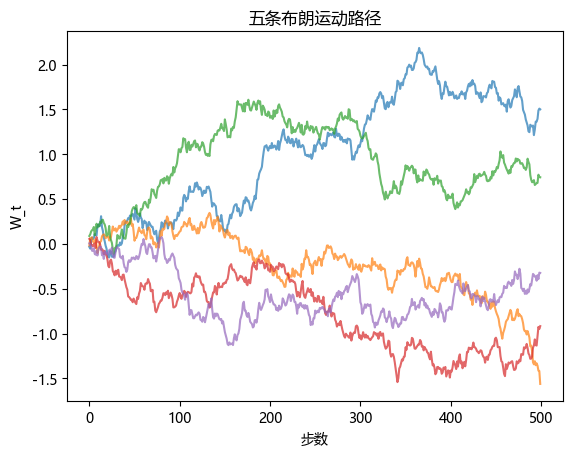

终点标准差 1.009 理论值 1.0


In [2]:

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(801)
n = 500
paths = np.cumsum(rng.normal(size=(5, n)) / np.sqrt(n), axis=1)

plt.plot(paths.T, alpha=0.7)
plt.title("五条布朗运动路径")
plt.xlabel("步数")
plt.ylabel("W_t")
plt.show()

many = np.cumsum(rng.normal(size=(20_000, n)) / np.sqrt(n), axis=1)
print("终点标准差", round(many[:, -1].std(ddof=1), 3), "理论值", 1.0)



**读数与应用**：五条路径的形状完全不同，但终点标准差接近 1。布朗运动的关键不是“某一条路径长什么样”，而是“所有路径的分布”。

**常见错误**：

1. 把布朗运动当成“价格”。价格通常是指数型的，布朗运动可以变负；价格要用几何布朗运动。
2. 把标准差按时间线性相加。方差相加，标准差按 $\sqrt t$。
3. 认为布朗路径“可导”。布朗路径几乎处处不可导，普通微积分不能直接套。

**停下来想一想**：布朗运动的增量独立，为什么价格水平不独立？

<details><summary>对照你的思路</summary>

价格是增量的累积和：$W_t=W_s+(W_t-W_s)$。增量独立，但 $W_t$ 包含 $W_s$，所以不同时刻的价格水平相关。增量独立和水平独立是两件事。

</details>

### 1.5 信息流与适应过程

随机过程不只是“一串数”，还带着信息：到时刻 $t$ 为止，你知道了什么？记作 $\mathcal F_t$。

- $\mathcal F_t$ 随 $t$ 增大（知道的越来越多）；
- 若 $X_t$ 在 $t$ 时刻已知，称它“适应” $\mathcal F_t$；
- 交易决策只能用 $\mathcal F_t$，不能用 $\mathcal F_{t+1}$。

这就是“未来函数”的数学版本：用了 $\mathcal F_{t+1}$ 的信息，回测就会虚高。后面讲鞅、风险中性，都要先指定“站在哪个信息集”。

---



## 2. 随机微分方程与欧拉步进

### 2.1 SDE

$$dX_t=a(X_t,t)\,dt+b(X_t,t)\,dW_t.$$

- $a$：漂移，单位时间的平均变化；
- $b$：扩散，单位根号时间的标准差；
- $dW_t$：布朗增量，量级 $\sqrt{dt}$。

### 2.2 欧拉步进

把 $dt$ 换成小步 $h$：

$$X_{t+h}\approx X_t+a(X_t,t)h+b(X_t,t)\sqrt h\,Z,\qquad Z\sim N(0,1).$$

这就是蒙特卡洛模拟的基本步。

### 2.3 手算

$X=100$，$a=2$ 元/年，$b=4$ 元/根号年，$h=0.25$ 年，$Z=-1$：

$$X_{t+h}=100+2\times0.25+4\times0.5\times(-1)=100+0.5-2=98.5.$$

### 2.4 代码：一步与三个情景



In [3]:

import numpy as np

def step(x, a, b, h, z):
    return x + a * h + b * np.sqrt(h) * z

print("一步", step(100, 2, 4, 0.25, -1))
print("三个情景", [round(float(step(100, 2, 4, 0.25, z)), 2) for z in [-1, 0, 1]])


一步 98.5
三个情景 [98.5, 100.5, 102.5]



**读数与应用**：同一个起点、同一个步长，不同的 $Z$ 给出不同的下一期价格。模拟很多条路径，才能得到分布。

**常见错误**：

1. 把 $b$ 当成“每步的标准差”。$b$ 是“每根号时间的标准差”，要乘 $\sqrt h$。
2. 用右端点的信息算 $a,b$。欧拉法用左端点（伊藤解释），否则会改变积分含义。
3. 步长太大。离散误差会累积，尤其是期权支付有折点时。

**停下来想一想**：为什么随机项要乘 $\sqrt h$，而不是 $h$？

<details><summary>对照你的思路</summary>

因为独立增量的方差相加：$n$ 步、每步方差 $h$，总方差 $nh=t$，所以每步标准差是 $\sqrt h$。如果乘 $h$，总方差会随步长变小，模拟结果会依赖网格。$\sqrt h$ 保证连续极限存在。

</details>

---



## 3. 二次变差与伊藤引理

### 3.1 二次变差

对一条路径，定义二次变差：

$$[X]_T=\lim_{\Delta t\to0}\sum_i(X_{t_{i+1}}-X_{t_i})^2.$$

**公式拆解**
- **符号**：$X$ 价格路径，$\Delta X_i$ 单步增量，$[X]_T$ 增量平方和（元²）。
- **结构**：每步增量先平方再求和、最后步长 $\to0$；正负抵消，只剩幅度。
- **代入**：$0\to1\to0$ 得 $1+1=2$；光滑路径会得 0。
- **边界**：布朗路径 $[X]_T=T$，不随网格消失。
- **用途**：算已实现波动率、解释伊藤修正；不是方差，是单条路径量。

普通光滑路径的二次变差为 0；布朗运动的二次变差为 $T$。这就是“布朗路径虽然连续，但足够粗糙”。

### 3.2 手算：$0\to1\to0$

路径 $W$：$0\to1\to0$，两段增量 $+1,-1$。

- 二次变差：$1^2+(-1)^2=2$；
- 终点平方差：$0^2-0^2=0$；
- 普通微积分会给 $0$，但实际多了 $2$。

对 $f(W)=W^2$：

$$f(W_T)-f(W_0)=2\sum W_i\Delta W_i+\sum(\Delta W_i)^2.$$

第一项是普通链式法则，第二项是伊藤修正项。

### 3.3 伊藤引理

对 $f(X,t)$，若 $dX=a\,dt+b\,dW$，则

$$df=\left(f_t+af_x+\frac12b^2f_{xx}\right)dt+bf_x\,dW.$$

**公式拆解**
- **符号**：$X$ 状态量，$a$ 漂移（元/年），$b$ 扩散（元/√年），$dW$ 布朗增量，$f$ 光滑。
- **结构**：漂移 $f_t+af_x+\frac12b^2f_{xx}$ 乘 $dt$，扩散 $bf_x\,dW$；多出项是曲率×方差。
- **代入**：$X=100,a=2,b=4,dt=0.01,Z=1$：$dX=0.42$，$f=x^2$ 得 $df=84.16$，普通链式 84。
- **边界**：$f$ 线性时修正为 0；有跳跃要另加跳项。
- **用途**：推 BS、算 Gamma 对冲误差；不能当高阶小量忽略。

多出来的 $\frac12b^2f_{xx}dt$，就是二次变差的贡献。它是“曲率 × 方差”。

### 3.4 代码：平方恒等式



In [4]:

import numpy as np

def account(path):
    d = np.diff(path)
    return 2 * path[:-1] @ d, d @ d, path[-1] ** 2 - path[0] ** 2

left, quadratic, total = account(np.array([0.0, 1.0, 0.0]))
print("0→1→0 的 2ΣWΔW、ΣΔW²、终点平方差", tuple(round(float(v), 3) for v in (left, quadratic, total)))

rng = np.random.default_rng(803)
for n in [100, 10_000]:
    W = np.r_[0, (rng.normal(size=n) / np.sqrt(n)).cumsum()]
    left, quadratic, total = account(W)
    print(n, "二次变差", round(quadratic, 4), "恒等式误差", round(left + quadratic - total, 12))


0→1→0 的 2ΣWΔW、ΣΔW²、终点平方差 (-2.0, 2.0, 0.0)
100 二次变差 0.8135 恒等式误差 -0.0
10000 二次变差 0.9837 恒等式误差 -0.0



**读数与应用**：$0\to1\to0$ 的二次变差是 2，不是 0；网格越细，随机路径的二次变差越接近 $T$。伊藤引理的修正项不是“数学技巧”，而是“布朗路径的平方不能忽略”。

**常见错误**：

1. 用普通链式法则 $df=f'dX$。漏掉 $\frac12f''b^2dt$。
2. 以为二次变差是“路径长度”。它是增量的平方和，不是绝对值和。
3. 忽略 $dt$ 与 $dW$ 的量级：$dW\sim\sqrt{dt}$，$dW^2\sim dt$。

**停下来想一想**：为什么普通光滑路径不需要伊藤修正？

<details><summary>对照你的思路</summary>

普通光滑路径的增量 $\Delta X\approx X'\Delta t$，平方后是 $(\Delta t)^2$；求和后随 $\Delta t\to0$ 趋于 0。布朗增量的量级是 $\sqrt{\Delta t}$，平方后是 $\Delta t$，求和后不趋于 0。差别就在增量的量级。

</details>

### 3.5 伊藤公式的推导（直觉版）

对 $f(X,t)$ 做二阶泰勒：

$$df=f_tdt+f_XdX+\frac12f_{XX}dX^2+\dots$$

代入 $dX=a\,dt+b\,dW$：

$$dX^2=b^2dt+2ab\,dt\,dW+a^2dt^2.$$

量级：$dt^2$ 和 $dt\,dW$ 都比 $dt$ 小，只有 $b^2dt$ 留下。所以

$$df=(f_t+af_X+\frac12b^2f_{XX})dt+bf_XdW.$$

关键不是“泰勒展开”，而是“$dW^2$ 不能丢”。

---



## 4. 几何布朗运动：为什么对数收益少半个方差

### 4.1 GBM

$$dS_t=\mu S_t\,dt+\sigma S_t\,dW_t.$$

价格按比例增长、按比例波动，保证价格为正。

### 4.2 对数变换

取 $f(S)=\ln S$：

$$f_S=\frac1S,\qquad f_{SS}=-\frac1{S^2}.$$

代入伊藤：

$$d\ln S=\left(\mu-\frac12\sigma^2\right)dt+\sigma\,dW.$$

**公式拆解**
- **符号**：$S$ 价格，$\mu$ 算术漂移（1/年），$\sigma$ 波动率（1/√年）。
- **结构**：对数漂移 $\mu-\frac12\sigma^2$（拖累 $\frac12\sigma^2$），扩散 $\sigma\,dW$。
- **代入**：$S_0=100,\mu=0.06,\sigma=0.2$：漂移 0.04，$W_1=0$ 时 $S_1=104.08$。
- **边界**：$\mu<\frac12\sigma^2$ 时典型路径跌、期望仍可能涨。
- **用途**：模拟、期权、长期复利；不是算术收益，不能当策略年化。

所以对数收益的漂移是 $\mu-\frac12\sigma^2$，不是 $\mu$。

### 4.3 手算

$S_0=100,\mu=0.06,\sigma=0.2,T=1$，若 $W_1=0$：

$$S_1=100\exp(0.06-0.02)=100e^{0.04}\approx104.08.$$

但很多路径的平均终值是 $100e^{0.06}\approx106.18$。先取指数再平均，不等于先平均再取指数。

### 4.4 代码：模拟均值



In [5]:

import numpy as np

S0, mu, sigma = 100.0, 0.06, 0.2
terminal = S0 * np.exp((mu - 0.5 * sigma ** 2) + sigma * np.random.default_rng(804).normal(size=100_000))

print("路径平均", round(terminal.mean(), 2))
print("理论平均", round(S0 * np.exp(mu), 2))
print("W=0 情景", round(S0 * np.exp(mu - 0.5 * sigma ** 2), 2))


路径平均 106.26
理论平均 106.18
W=0 情景 104.08



**读数与应用**：路径平均接近 $S_0e^{\mu T}$，而不是 $S_0e^{(\mu-\sigma^2/2)T}$。因为 $e^X$ 是凸函数，$E[e^X]\ge e^{E[X]}$。

**常见错误**：

1. 把对数收益的均值当成算术收益的均值。两者差半个方差。
2. 用 $\mu$ 直接模拟价格，忘了 $-\frac12\sigma^2$。长期会高估。
3. 认为 GBM 能描述跳空。GBM 路径连续，跳空要加泊松跳跃。

**停下来想一想**：为什么先涨 10% 再跌 10%，结果不是回到原点？

<details><summary>对照你的思路</summary>

$1.1\times0.9=0.99$，亏 1%。对数收益是 $\ln1.1+\ln0.9=\ln0.99$。波动越大，这种“几何平均低于算术平均”的效应越强；连续模型里的 $-\frac12\sigma^2$ 就是它的局部表达。

</details>

### 4.5 GBM 的分布

由 $d\ln S=(\mu-\frac12\sigma^2)dt+\sigma dW$，

$$\ln S_T\sim N\left(\ln S_0+(\mu-\frac12\sigma^2)T,\ \sigma^2T\right).$$

所以 $S_T$ 是对数正态：

$$E[S_T]=S_0e^{\mu T},\qquad \operatorname{Median}(S_T)=S_0e^{(\mu-\frac12\sigma^2)T}.$$

均值高于中位数，因为右尾长。用 GBM 做情景分析时，要区分“均值路径”和“中位数路径”。

---



## 5. 鞅与风险中性：公平游戏怎样定价

### 5.1 条件期望

给定今天的信息 $\mathcal F_t$，对未来的期望记作 $E[X_{t+1}\mid\mathcal F_t]$。它回答“站在今天，明天平均会怎样”。

### 5.2 鞅

若

$$E[M_{t+1}\mid\mathcal F_t]=M_t,$$

称 $M_t$ 是鞅：给定今天的信息，明天的条件期望等于今天。公平游戏、无漂移的价格（在风险中性测度下）都是鞅。

### 5.3 风险中性定价

设股票今天 100，明天可能 120 或 90，无息。要找“风险中性概率” $p$，使股票价格是鞅：

$$120p+90(1-p)=100\quad\Rightarrow\quad p=\frac13.$$

看涨执行价 100，支付为 20 或 0：

$$C=20\times\frac13+0\times\frac23=\frac{20}{3}\approx6.67.$$

真实上涨概率即使是 0.6，也不影响这个无套利价格；真实概率只影响真实世界的期望收益。

### 5.4 代码：风险中性概率



In [6]:

p = (100 - 90) / (120 - 90)
print("风险中性上涨概率", round(p, 4))
print("股票均值", 120 * p + 90 * (1 - p))
print("看涨 K=100 的价格", round(20 * p, 4))


风险中性上涨概率 0.3333
股票均值 100.0
看涨 K=100 的价格 6.6667



**读数与应用**：风险中性概率不是“真实概率”，而是“让可交易价格成为鞅的权重”。它由可复制组合决定，不由你的主观判断决定。

**常见错误**：

1. 把风险中性概率当成真实概率。真实概率影响期望收益，不影响无套利价格。
2. 忘记贴现。无息时可以不贴现；有息时要乘 $e^{-rT}$。
3. 在真实测度下给期权定价。真实测度下的期望收益包含风险溢价，不是无套利价格。

**停下来想一想**：如果真实上涨概率是 0.9，看涨价格会变吗？

<details><summary>对照你的思路</summary>

在无套利、可复制的假设下，不会变。价格由复制成本决定：买 $\Delta$ 股、借/贷现金，就能复制期权支付。真实概率 0.9 会让“持有股票的期望收益”变高，但也会让贴现/风险溢价相应调整，最终无套利价格不变。

</details>

### 5.5 测度变换的直觉

真实世界有漂移 $\mu$，风险中性世界把漂移换成 $r$（对期货是 0）。两个世界的概率不同，但可交易价格的无套利关系不变。

测度变换不是“改历史”，而是“换一套定价权重”。Girsanov 定理给出了这套权重的数学形式；本章只需要记住：

- 真实概率用于预测；
- 风险中性概率用于定价；
- 两者由“风险溢价”连接。

一个常见误解：风险中性世界的人“不关心风险”。不是；风险中性是“把风险溢价从漂移里拿掉”，不是“风险消失”。

---



## 6. OU 过程：价差怎样向均值回归

### 6.1 方程

$$dX_t=\kappa(\theta-X_t)\,dt+\sigma\,dW_t.$$

**公式拆解**
- **符号**：$X$ 价差（元），$\theta$ 均值，$\kappa$ 回归速度，$\sigma$ 波动。
- **结构**：漂移 $\kappa(\theta-X)$ 拉回均值；半衰期 $\ln2/\kappa$，条件均值 $\theta+(X_0-\theta)e^{-\kappa t}$。
- **代入**：$\theta=10,\kappa=\ln2,X_0=14$：$t=1$ 得 12，$t=2$ 得 11。
- **边界**：$\kappa\to0$ 退化为随机漫步；$\kappa<0$ 发散。
- **用途**：价差/基差均值回归；半衰期不是回归保证。

- $\theta$：长期均值；
- $\kappa$：回归速度；
- $\sigma$：波动。

$X$ 高于 $\theta$ 时漂移为负，低于 $\theta$ 时为正，所以会被拉回。

### 6.2 条件均值与方差

从 $X_0$ 出发，经过 $t$：

$$E[X_t\mid X_0]=\theta+(X_0-\theta)e^{-\kappa t},$$

$$\operatorname{Var}(X_t\mid X_0)=\frac{\sigma^2}{2\kappa}\left(1-e^{-2\kappa t}\right).$$

### 6.3 半衰期

偏离减半的时间：

$$t_{1/2}=\frac{\ln2}{\kappa}.$$

$\kappa=\ln2$ 时，半衰期正好 1 期。

### 6.4 手算

$\theta=10,\kappa=\ln2,X_0=14,\sigma=2$：

- 1 期后均值：$10+4\times0.5=12$；
- 2 期后：$10+4\times0.25=11$；
- 半衰期：1 期。

### 6.5 代码：条件均值与标准差



In [7]:

import numpy as np

kappa, theta, x0, sigma = np.log(2), 10.0, 14.0, 2.0
for h in [1, 2, 5]:
    mean = theta + (x0 - theta) * np.exp(-kappa * h)
    var = sigma ** 2 * (1 - np.exp(-2 * kappa * h)) / (2 * kappa)
    print("期数", h, "条件均值", round(mean, 3), "条件标准差", round(np.sqrt(var), 3))
print("半衰期", round(np.log(2) / kappa, 3))


期数 1 条件均值 12.0 条件标准差 1.471
期数 2 条件均值 11.0 条件标准差 1.645
期数 5 条件均值 10.125 条件标准差 1.698
半衰期 1.0



**读数与应用**：均值按指数衰减，方差从 0 逐渐升到长期方差 $\sigma^2/(2\kappa)$。半衰期是条件均值的速度，不是“价格一定回来”的保证。

**常见错误**：

1. 把 OU 的半衰期当成“持仓时间”。它是条件均值的衰减速度，不含成本、止损、成交延迟。
2. 用 OU 拟合价格。价格通常有单位根/趋势；OU 更适合价差、基差、利差。
3. 忽略参数不稳定性。$\theta,\kappa$ 会随供需/制度变化，滚动估计更稳。

**停下来想一想**：OU 的长期方差是多少？

<details><summary>对照你的思路</summary>

令 $t\to\infty$，$e^{-2\kappa t}\to0$，方差趋于 $\sigma^2/(2\kappa)$。$\kappa$ 越大（回归越快），长期方差越小；$\sigma$ 越大，长期方差越大。

</details>

---



## 7. 泊松跳跃：为什么再勤调仓也会漏掉跳空

### 7.1 跳扩散

$$dX_t=a\,dt+b\,dW_t+J\,dN_t.$$

- $N_t$：泊松过程，强度 $\lambda$（单位时间平均跳跃次数）；
- $J$：每次跳跃的幅度（可正可负）；
- 布朗项在短时间里变小，跳跃项不会因为时间切细而变小。

### 7.2 手算

每天平均 0.2 次跳跃，每次下跳 5 点：

$$P(\text{无跳})=e^{-0.2}\approx0.819,$$

跳跃部分的期望：$-5\times0.2=-1$ 点/天。

### 7.3 为什么 Delta 对冲失效

Delta 对冲假设价格连续变化，可以用标的的微小变动抵消期权的微小变动。跳空时，价格一次性跳过好几个价位，Delta 来不及调整；Gamma 和 Vega 也会跳变。**跳空风险不能靠“更勤调仓”完全对冲。**

### 7.4 代码：模拟跳跃



In [8]:

import numpy as np

rng = np.random.default_rng(807)
counts = rng.poisson(0.2, size=30_000)
print("无跳比例", round((counts == 0).mean(), 4), "理论", round(np.exp(-0.2), 4))
print("跳跃部分平均损益", round((-5 * counts).mean(), 4))


无跳比例 0.8154 理论 0.8187
跳跃部分平均损益 -1.0247



**读数与应用**：模拟的无跳比例接近 $e^{-0.2}$，跳跃平均损益接近 -1。真实跳幅可正可负、可大可小；跳跃方向还可能和波动率聚集相关。

**常见错误**：

1. 用连续模型给跳空风险定价。尾部会被低估。
2. 认为“调仓越勤越安全”。跳空发生在两次调仓之间，调仓频率救不了。
3. 把跳幅当常数。真实跳幅是随机的，甚至和消息面相关。

**停下来想一想**：为什么跳空会让期权卖方风险更大？

<details><summary>对照你的思路</summary>

卖方负 Gamma、负 Vega；跳空时标的一次性大动，Gamma 让亏损非线性放大，Vega 也可能跳升。买方最多亏权利金，卖方理论上亏损很大。跳空是卖方策略的“尾部杀手”。

</details>

### 7.5 跳扩散与微笑

纯 GBM 的隐含波动率曲线是平的；真实期权有“微笑/偏斜”。加入跳跃后，尾部变厚，虚值期权变贵，曲线两端翘起。

校准跳扩散模型，通常要估：

- 跳跃强度 $\lambda$；
- 平均跳幅和跳幅波动；
- 扩散波动率 $\sigma$。

参数不是唯一的：不同的跳跃设定可以拟合出相似的微笑。这就是“模型风险”。

---



## 8. Hawkes 过程：一笔订单为什么引来更多订单

### 8.1 强度

泊松过程的强度是常数 $\lambda$；Hawkes 让强度被历史事件“点燃”：

$$\lambda(t)=\mu+\sum_{t_i<t}\alpha e^{-\beta(t-t_i)}.$$

- $\mu$：背景强度；
- $\alpha$：每次事件给强度加的“火花”；
- $\beta$：衰减速度；
- 分支比 $\alpha/\beta$：一个事件平均诱发多少个后续事件。

### 8.2 手算

$\mu=0.5,\alpha=0.8,\beta=2$：

- 刚发生一次事件：$\lambda=0.5+0.8=1.3$；
- 1 秒后：$0.5+0.8e^{-2}\approx0.608$；
- 分支比 $0.8/2=0.4$。

### 8.3 为什么有用

订单流、成交、波动率都有“成簇”特征：一笔大单引来跟风，一次波动引来更多波动。Hawkes 把这种“自激”写成强度，比常数泊松更贴近微观结构。

### 8.4 代码：强度曲线



In [9]:

import numpy as np

events = np.array([0.0, 0.5])
for t in [0.01, 0.49, 0.51, 1.5]:
    past = events[events < t]
    intensity = 0.5 + (0.8 * np.exp(-2 * (t - past))).sum()
    print("t", t, "强度", round(intensity, 3))

print("分支比", 0.8 / 2)


t 0.01 强度 1.284
t 0.49 强度 0.8
t 0.51 强度 1.573
t 1.5 强度 0.648
分支比 0.4



**读数与应用**：事件发生后强度跳升，然后按指数衰减；分支比小于 1 时过程稳定，接近 1 时事件会成簇、甚至“爆炸”。

**常见错误**：

1. 把强度当概率。强度是单位时间的到达率，短时间概率约 $\lambda h$。
2. 忽略分支比。$\alpha/\beta\ge1$ 时，模型可能不稳定。
3. 用 Hawkes 拟合没有逐笔数据的价格。没有事件时间，估不出强度。

**停下来想一想**：分支比 0.4 意味着什么？

<details><summary>对照你的思路</summary>

一个事件平均直接诱发 0.4 个后续事件；0.4 个后续事件又各自诱发 0.4 个，总诱发数是一个几何级数 $0.4+0.4^2+\dots=0.4/(1-0.4)\approx0.667$。分支比越接近 1，簇越大、越持久。

</details>

### 8.5 Hawkes 的估计与风险

估计 Hawkes 通常用最大似然：给定事件时间，写出强度的似然，优化 $\mu,\alpha,\beta$。数据要求是逐笔事件时间，不是分钟 K 线。

风险：

- 分支比接近 1 时，过程不稳定，样本外可能“爆炸”；
- 事件定义（撤单、成交、大单）会改变强度；
- 非平稳性：开盘/收盘、消息面会改变背景强度。

所以 Hawkes 更适合做微观结构研究，不是直接拿来预测日线方向。

---



## 9. 多维伊藤：两条腿一起动时的交叉项

### 9.1 二维伊藤

对 $f(X,Y)$：

$$df=f_XdX+f_YdY+\frac12\left(f_{XX}dX^2+2f_{XY}dXdY+f_{YY}dY^2\right).$$

若 $dX=a\,dt+b\,dW_1$，$dY=c\,dt+d\,dW_2$，相关系数 $\rho$，则

$$dXdY=\rho bd\,dt.$$

交叉项来自“两条腿一起动”。

### 9.2 手算

$f=XY$，$X=10,Y=20$，$X$ 增 2、$Y$ 增 3：

$$\Delta(XY)=12\times23-200=76.$$

一阶项：$10\times3+20\times2=70$；交叉项：$2\times3=6$。$70+6=76$。

### 9.3 和期权的关系

若 $X$ 是标的、$Y$ 是隐波，$f_{XY}$ 就是 Vanna：标的和波动率同时动时的交叉敏感度。只会背“Delta、Vega”，解释不了两者一起动时的损益。

### 9.4 代码：交叉项



In [10]:

import numpy as np

rng = np.random.default_rng(809)
n = 20_000
rho, dt = 0.6, 1 / n
z, u = rng.normal(size=(2, n))
dx = 2 * np.sqrt(dt) * z
dy = 3 * np.sqrt(dt) * (rho * z + np.sqrt(1 - rho * rho) * u)

X = np.r_[10, 10 + dx.cumsum()]
Y = np.r_[20, 20 + dy.cumsum()]
change = X[-1] * Y[-1] - X[0] * Y[0]
cross = dx @ dy

print("完整乘积变化", round(change, 4))
print("交叉项", round(cross, 4), "理论", round(rho * 2 * 3, 4))


完整乘积变化 52.7167
交叉项 3.5879 理论 3.6



**读数与应用**：交叉项接近 $\rho\times2\times3=3.6$。相关系数越大，两条腿一起动得越多，交叉项越重要。

**常见错误**：

1. 只保留一阶项。两条腿相关时，交叉项不能忽略。
2. 把相关系数当成“常数”。危机时相关性会变，交叉项也会变。
3. 忘记 $dXdY$ 的量级是 $dt$，不是 $dW$。

**停下来想一想**：如果两条腿完全负相关，交叉项会怎样？

<details><summary>对照你的思路</summary>

交叉项为负：一条腿涨、另一条腿跌，乘积变化被部分抵消。组合的风险可能下降，但如果两条腿的权重没配好，仍可能有大的方向暴露。负相关是分散化的来源，不是“没有风险”。

</details>

---



## 本章小结

### 一张公式表

| 概念 | 公式 | 用途 |
|---|---|---|
| 布朗运动 | $W_t\sim N(0,t)$ | 随机冲击的基准 |
| SDE | $dX=a\,dt+b\,dW$ | 路径模型 |
| 欧拉步 | $X_{t+h}\approx X+a h+b\sqrt h Z$ | 模拟 |
| 二次变差 | $[W]_T=T$ | 伊藤修正 |
| 伊藤引理 | $df=(f_t+af_x+\frac12b^2f_{xx})dt+bf_xdW$ | 随机链式法则 |
| GBM | $d\ln S=(\mu-\frac12\sigma^2)dt+\sigma dW$ | 价格模型 |
| 鞅 | $E[M_{t+1}\mid\mathcal F_t]=M_t$ | 公平游戏 |
| OU | $dX=\kappa(\theta-X)dt+\sigma dW$ | 均值回归 |
| 跳扩散 | $dX=a\,dt+b\,dW+J\,dN$ | 跳空 |
| Hawkes | $\lambda(t)=\mu+\sum\alpha e^{-\beta(t-t_i)}$ | 订单聚集 |
| 二维伊藤 | $dXdY=\rho bd\,dt$ | 交叉项/Vanna |

### 八句话

1. 布朗运动的方差按时间线性增长，标准差按 $\sqrt t$。
2. SDE 的随机项乘 $\sqrt h$，不是 $h$。
3. 布朗路径的二次变差不为 0，所以链式法则多一项。
4. 伊藤修正项是“曲率 × 方差”。
5. 对数收益的漂移比算术漂移少半个方差。
6. 风险中性概率不是真实概率，它让可交易价格成为鞅。
7. 跳空不能靠更勤的 Delta 对冲消除。
8. 两条腿相关时，交叉项不能忽略；这就是 Vanna 的来源。

---

## 本章习题

**1.** 布朗运动 $W_t$，$t=9$，波动率参数 $\sigma=2$。求 $\operatorname{Var}(X_t)$、$\operatorname{SD}(X_t)$。

**2.** SDE 一步：$X=100,a=1,b=3,h=0.25,Z=-2$。求下一步。

**3.** 路径 $0\to1\to0$。求二次变差；伊藤修正项是多少？

**4.** GBM：$\mu=0.08,\sigma=0.2$。求对数收益的年化漂移。

**5.** 股票 100，明天 120 或 90，无息，看涨 K=100。求风险中性概率和期权价格。

**6.** OU：$\theta=10,\kappa=\ln2,X_0=14$。求 1 期、2 期后的条件均值。

**7.** 泊松跳跃：$\lambda=0.5$ 次/天。求一天无跳概率、期望跳跃次数。

**8.** Hawkes：$\mu=0.5,\alpha=0.8,\beta=2$。求分支比、事件刚发生后的强度。

<details><summary>参考答案</summary>

**1.** $\operatorname{Var}=4\times9=36$；$\operatorname{SD}=6$。

**2.** $100+1\times0.25+3\times0.5\times(-2)=100+0.25-3=97.25$。

**3.** 二次变差 $1^2+(-1)^2=2$。对 $f(W)=W^2$，伊藤修正项是 $\frac12 f''[W]_T=\frac12\times2\times2=2$；所以 $2\sum W_i\Delta W_i+\sum(\Delta W_i)^2=0$，而不是普通微积分给的 0 修正。

**4.** $0.08-0.5\times0.2^2=0.08-0.02=0.06$。

**5.** $p=(100-90)/(120-90)=1/3$；看涨价格 $20/3\approx6.67$。

**6.** 1 期：$10+4\times0.5=12$；2 期：$10+4\times0.25=11$。

**7.** $P(0)=e^{-0.5}\approx0.6065$；期望跳跃次数 0.5。

**8.** 分支比 $0.8/2=0.4$；事件刚发生后强度 $0.5+0.8=1.3$。

</details>

---

## 参考资料

- Karatzas, I. & Shreve, S. E. *Brownian Motion and Stochastic Calculus*（布朗运动、伊藤积分）。
- Øksendal, B. *Stochastic Differential Equations*（SDE 的标准教材）。
- Hull, J. C. *Options, Futures, and Other Derivatives*（GBM、Ito、风险中性）。
- Bacry, E., Mastromatteo, I. & Muzy, J.-F. *Hawkes Processes in Finance*（订单流自激）。
